In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("heart.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [4]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["target"].value_counts())

display(df.describe().T)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Missing values in each column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal  

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


In [5]:
# Check duplicate rows
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())

# Check exact duplicate rows including the target
print("\nDuplicate rows by target:")
print(df.loc[df.duplicated(keep=False), "target"].value_counts())

# Target distribution
print("\nTarget distribution:")
print(df["target"].value_counts())

print("\nTarget percentage:")
print((df["target"].value_counts(normalize=True) * 100).round(2))

Total rows: 1025
Duplicate rows: 723

Duplicate rows by target:
target
1    526
0    499
Name: count, dtype: int64

Target distribution:
target
1    526
0    499
Name: count, dtype: int64

Target percentage:
target
1    51.32
0    48.68
Name: proportion, dtype: float64


In [6]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

print("\nUpdated target distribution:")
print(df["target"].value_counts())

Shape after removing duplicates: (302, 14)
Remaining duplicates: 0

Updated target distribution:
target
1    164
0    138
Name: count, dtype: int64


In [7]:
# Separate input features and target
X = df.drop(columns=["target"])
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values before imputation:")
print(X.isnull().sum().sum())

Features shape: (302, 13)
Target shape: (302,)

Missing values before imputation:
0


In [8]:
from sklearn.model_selection import train_test_split

# 60% training, 40% temporary
X_train, X_temp, y_train, y_temp = train_test_split(               
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Split the remaining 40% into 20% validation and 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (181, 13)
Validation: (60, 13)
Testing: (61, 13)


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

baseline_model.fit(X_train, y_train)

print("Logistic Regression baseline trained successfully.")

Logistic Regression baseline trained successfully.


Validation Accuracy: 0.7833
Validation Precision: 0.8333
Validation Recall: 0.7576
Validation F1: 0.7937
Validation ROC-AUC: 0.8575

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.81      0.77        27
           1       0.83      0.76      0.79        33

    accuracy                           0.78        60
   macro avg       0.78      0.79      0.78        60
weighted avg       0.79      0.78      0.78        60



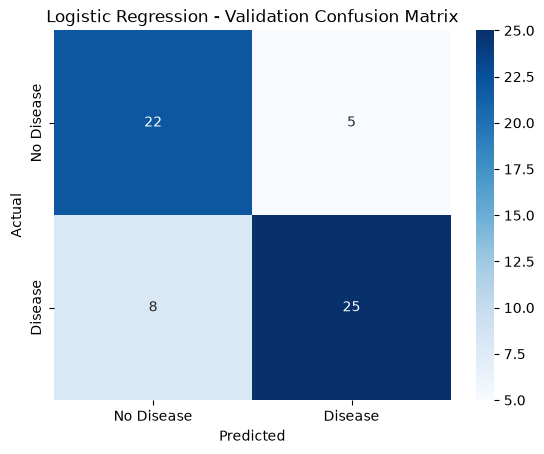

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

y_val_pred = baseline_model.predict(X_val)
y_val_prob = baseline_model.predict_proba(X_val)[:, 1]

print("Validation Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Validation Precision:", round(precision_score(y_val, y_val_pred), 4))
print("Validation Recall:", round(recall_score(y_val, y_val_pred), 4))
print("Validation F1:", round(f1_score(y_val, y_val_pred), 4))
print("Validation ROC-AUC:", round(roc_auc_score(y_val, y_val_prob), 4))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

sns.heatmap(
    confusion_matrix(y_val, y_val_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Validation Confusion Matrix")
plt.show() 

In [11]:
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import pandas as pd
import numpy as np

# F1 balances precision and recall during hyperparameter tuning
# Each pipeline fits preprocessing only on the training data.

linear_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(max_iter=10000, random_state=42))
])

rbf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

# Linear SVM: tune C
linear_grid = {
    "svm__C": [0.01, 0.1, 1, 10, 100]
}

linear_search = GridSearchCV(
    linear_pipeline,
    linear_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

linear_search.fit(X_train, y_train)

# RBF SVM: tune both C and gamma
rbf_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1]
}

rbf_search = GridSearchCV(
    rbf_pipeline,
    rbf_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

rbf_search.fit(X_train, y_train)

print("Best Linear SVM parameters:", linear_search.best_params_)
print("Best Linear SVM CV F1:", round(linear_search.best_score_, 4))

print("\nBest RBF SVM parameters:", rbf_search.best_params_)
print("Best RBF SVM CV F1:", round(rbf_search.best_score_, 4))

Best Linear SVM parameters: {'svm__C': 0.01}
Best Linear SVM CV F1: 0.8284

Best RBF SVM parameters: {'svm__C': 1, 'svm__gamma': 0.01}
Best RBF SVM CV F1: 0.8476


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

models = {
    "Logistic Regression": baseline_model,
    "Linear SVM": linear_search.best_estimator_,
    "RBF SVM": rbf_search.best_estimator_
}

validation_results = []

for name, model in models.items():
    pred = model.predict(X_val)
    scores = model.decision_function(X_val)

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall / Sensitivity": recall_score(y_val, pred, zero_division=0),
        "F1 Score": f1_score(y_val, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, scores)
    })

validation_results = pd.DataFrame(validation_results)
display(validation_results.round(4))

,Model,Accuracy,Precision,Recall / Sensitivity,F1 Score,ROC-AUC
0,Logistic Regression,0.7833,0.8333,0.7576,0.7937,0.8575
1,Linear SVM,0.8000,0.8182,0.8182,0.8182,0.8698
2,RBF SVM,0.8167,0.8235,0.8485,0.8358,0.8878


Test Accuracy: 0.8197
Test Precision: 0.8235
Test Recall / Sensitivity: 0.8485
Test Specificity: 0.7857
Test F1 Score: 0.8358

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.79      0.80        28
           1       0.82      0.85      0.84        33

    accuracy                           0.82        61
   macro avg       0.82      0.82      0.82        61
weighted avg       0.82      0.82      0.82        61



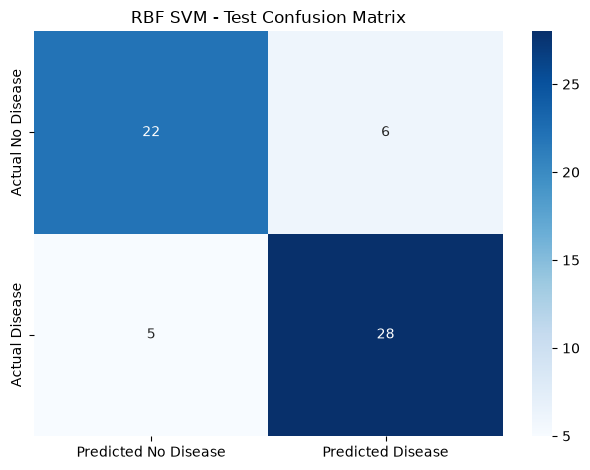

In [13]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Choose the RBF SVM as a candidate; compare results with Linear SVM.
best_model = rbf_search.best_estimator_

y_test_pred = best_model.predict(X_test)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_test_pred, labels=[0, 1]
).ravel()

sensitivity = tp / (tp + fn) if (tp + fn) else 0
specificity = tn / (tn + fp) if (tn + fp) else 0

print("Test Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Test Precision:", round(precision_score(y_test, y_test_pred, zero_division=0), 4))
print("Test Recall / Sensitivity:", round(sensitivity, 4))
print("Test Specificity:", round(specificity, 4))
print("Test F1 Score:", round(f1_score(y_test, y_test_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

sns.heatmap(
    [[tn, fp], [fn, tp]],
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No Disease", "Predicted Disease"],
    yticklabels=["Actual No Disease", "Actual Disease"]
)
plt.title("RBF SVM - Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [14]:
test_results = []

for name, model in {
    "Linear SVM": linear_search.best_estimator_,
    "RBF SVM": rbf_search.best_estimator_
}.items():
    pred = model.predict(X_test)
    scores = model.decision_function(X_test)
    tn_i, fp_i, fn_i, tp_i = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Sensitivity": tp_i / (tp_i + fn_i) if (tp_i + fn_i) else 0,
        "Specificity": tn_i / (tn_i + fp_i) if (tn_i + fp_i) else 0,
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, scores)
    })

test_results = pd.DataFrame(test_results)
display(test_results.round(4))

test_results.to_csv("svm_heart_disease_test_comparison.csv", index=False)
print("Saved: svm_heart_disease_test_comparison.csv")

,Model,Accuracy,Precision,Sensitivity,Specificity,F1 Score,ROC-AUC
0,Linear SVM,0.8197,0.8438,0.8182,0.8214,0.8308,0.9080
1,RBF SVM,0.8197,0.8235,0.8485,0.7857,0.8358,0.9026


Saved: svm_heart_disease_test_comparison.csv


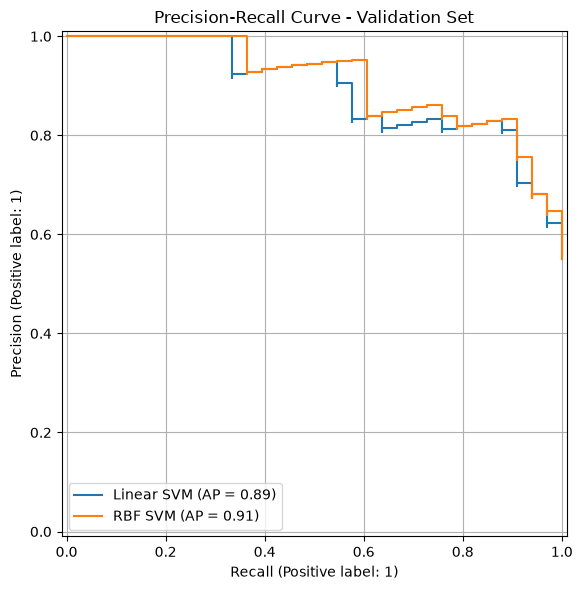

In [15]:
from sklearn.metrics import PrecisionRecallDisplay

plt.figure(figsize=(8, 6))

for name, model in {
    "Linear SVM": linear_search.best_estimator_,
    "RBF SVM": rbf_search.best_estimator_
}.items():
    scores = model.decision_function(X_val)
    PrecisionRecallDisplay.from_predictions(
        y_val, scores, name=name, ax=plt.gca()
    )

plt.title("Precision-Recall Curve - Validation Set")
plt.grid(True)
plt.tight_layout()
plt.show()

Selected threshold: -0.912
Validation sensitivity at threshold: 0.9697
Validation precision at threshold: 0.6809

Test results with adjusted threshold
Threshold: -0.912
Sensitivity: 1.0
Specificity: 0.5714
Precision: 0.7333
F1 Score: 0.8462


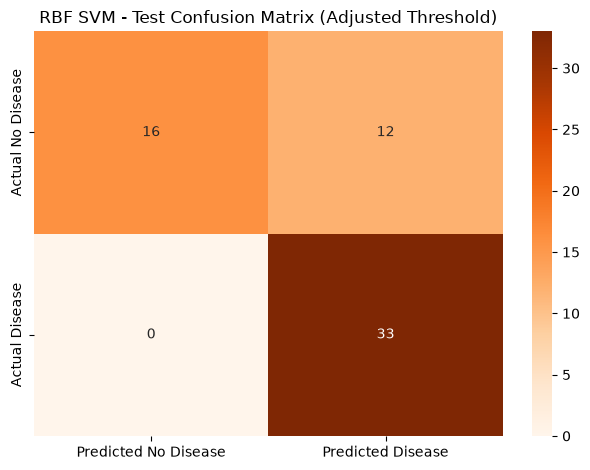

In [16]:
from sklearn.metrics import precision_recall_curve

# Use validation scores to select the threshold
threshold_model = rbf_search.best_estimator_
val_scores = threshold_model.decision_function(X_val)

precision, recall, thresholds = precision_recall_curve(
    y_val, val_scores
)

target_sensitivity = 0.95

# recall and precision have one more element than thresholds
eligible = np.where(recall[:-1] >= target_sensitivity)[0]

if len(eligible) > 0:
    # Highest threshold that still meets the target sensitivity
    chosen_idx = eligible[np.argmax(thresholds[eligible])]
    selected_threshold = thresholds[chosen_idx]
    print("Selected threshold:", round(selected_threshold, 4))
    print("Validation sensitivity at threshold:", round(recall[chosen_idx], 4))
    print("Validation precision at threshold:", round(precision[chosen_idx], 4))
else:
    # If impossible, use the threshold that maximizes validation recall
    chosen_idx = np.argmax(recall[:-1])
    selected_threshold = thresholds[chosen_idx]
    print("Target sensitivity could not be reached.")
    print("Using threshold with highest validation recall.")

# Evaluate the selected threshold ONCE on the held-out test set
test_scores = threshold_model.decision_function(X_test)
y_test_adjusted = (test_scores >= selected_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_test_adjusted, labels=[0, 1]
).ravel()

print("\nTest results with adjusted threshold")
print("Threshold:", round(selected_threshold, 4))
print("Sensitivity:", round(tp / (tp + fn), 4) if tp + fn else 0)
print("Specificity:", round(tn / (tn + fp), 4) if tn + fp else 0)
print("Precision:", round(precision_score(y_test, y_test_adjusted, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_test_adjusted, zero_division=0), 4))

sns.heatmap(
    [[tn, fp], [fn, tp]],
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Predicted No Disease", "Predicted Disease"],
    yticklabels=["Actual No Disease", "Actual Disease"]
)
plt.title("RBF SVM - Test Confusion Matrix (Adjusted Threshold)")
plt.tight_layout()
plt.show()

In [ ]:
linear_model = linear_search.best_estimator_

# Extract the fitted Linear SVM and its coefficients
svm_classifier = linear_model.named_steps["svm"]
coefficients = svm_classifier.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefficients,
    "Absolute Importance": np.abs(coefficients)
}).sort_values("Absolute Importance", ascending=False)

top_5_features = feature_importance.head(5)

print("Top 5 features by absolute Linear SVM coefficient:")
display(top_5_features.round(4))

Top 5 features by absolute Linear SVM coefficient:


,Feature,Coefficient,Absolute Importance
2,cp,0.2441,0.2441
11,ca,-0.1759,0.1759
1,sex,-0.1627,0.1627
8,exang,-0.1545,0.1545
7,thalach,0.1455,0.1455


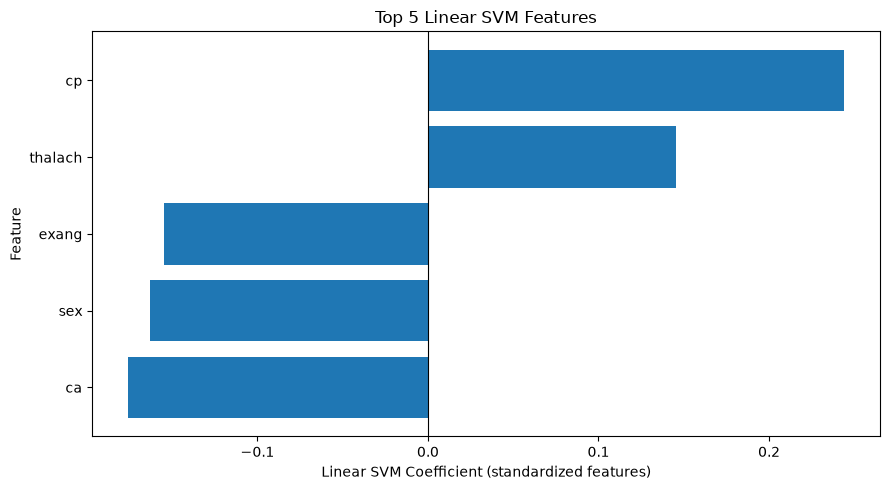

In [18]:
plot_data = top_5_features.sort_values("Coefficient")

plt.figure(figsize=(9, 5))
plt.barh(
    plot_data["Feature"],
    plot_data["Coefficient"]
)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Linear SVM Coefficient (standardized features)")
plt.ylabel("Feature")
plt.title("Top 5 Linear SVM Features")
plt.tight_layout()
plt.show()

In [19]:
clinical_context = {
    "age": "Older age is associated with increased cardiovascular risk.",
    "sex": "Sex is associated with differences in cardiovascular risk.",
    "cp": "Chest pain type is clinically relevant to heart disease assessment.",
    "trestbps": "Elevated resting blood pressure is a cardiovascular risk factor.",
    "chol": "Elevated cholesterol can contribute to cardiovascular risk.",
    "fbs": "Elevated fasting blood sugar may indicate metabolic risk.",
    "restecg": "Resting ECG abnormalities can provide cardiac information.",
    "thalach": "Maximum heart rate achieved can be informative.",
    "exang": "Exercise-induced angina is clinically relevant.",
    "oldpeak": "ST depression during exercise can provide diagnostic information.",
    "slope": "The exercise ST-segment slope can provide diagnostic information.",
    "ca": "Major vessels visualized by fluoroscopy can be diagnostically informative.",
    "thal": "The recorded thalassemia-related test category can be informative."
}

print("Clinical interpretation of top five features:\n")

for _, row in top_5_features.iterrows():
    feature = row["Feature"]
    direction = (
        "toward heart disease"
        if row["Coefficient"] > 0
        else "toward no heart disease"
    )

    print(f"{feature}: coefficient = {row['Coefficient']:.4f}")
    print("  Direction:", direction)
    print("  Context:", clinical_context.get(
        feature, "Review the feature definition."
    ))
    print()

Clinical interpretation of top five features:

cp: coefficient = 0.2441
  Direction: toward heart disease
  Context: Chest pain type is clinically relevant to heart disease assessment.

ca: coefficient = -0.1759
  Direction: toward no heart disease
  Context: Major vessels visualized by fluoroscopy can be diagnostically informative.

sex: coefficient = -0.1627
  Direction: toward no heart disease
  Context: Sex is associated with differences in cardiovascular risk.

exang: coefficient = -0.1545
  Direction: toward no heart disease
  Context: Exercise-induced angina is clinically relevant.

thalach: coefficient = 0.1455
  Direction: toward heart disease
  Context: Maximum heart rate achieved can be informative.



In [20]:
feature_importance.to_csv(
    "linear_svm_feature_importance.csv",
    index=False
)

print("Saved:")
print("- svm_heart_disease_test_comparison.csv")
print("- linear_svm_feature_importance.csv")

Saved:
- svm_heart_disease_test_comparison.csv
- linear_svm_feature_importance.csv
